In [4]:
%pip install -q gensim

In [56]:
from pathlib import Path
import re
import random
from time import perf_counter

from tqdm.auto import tqdm

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_fscore_support, f1_score, classification_report, ConfusionMatrixDisplay

from gensim.models import Word2Vec, FastText

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torch.nn.utils.rnn import pack_padded_sequence

from transformers import BertConfig, BertForSequenceClassification, AutoTokenizer, AutoModelForSequenceClassification

from IPython.display import display

In [21]:
from google.colab import drive

# drive.mount("/content/drive")

In [22]:
!nvidia-smi

Thu Nov 19 19:05:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8             13W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [23]:
device = "cuda" if torch.cuda.is_available() else "cpu"

device

'cuda'

In [24]:
SEED = 21
random.seed(SEED)
np.random.seed(SEED)

In [25]:
DATA_PATH = Path("drive/MyDrive/subset_data.csv.zip")

In [26]:
from zipfile import ZipFile

with ZipFile(DATA_PATH) as archive:
    with archive.open("subset_data.csv") as file:
        data = pd.read_csv(file)

In [27]:
data.shape

(1780822, 2)

In [28]:
data.head(5)

,comment_text,label
0,"This is so cool. It's like, 'would you want yo...",0
1,Thank you!! This would make my life a lot less...,0
2,This is such an urgent design problem; kudos t...,0
3,Is this something I'll be able to install on m...,0
4,haha you guys are a bunch of losers.,1


In [29]:
data.isna().sum().to_frame("missing")

,missing
comment_text,0
label,0


In [30]:
subset, _ = train_test_split(
    data, train_size=100_000, stratify=data["label"], random_state=SEED,
)
train_full, test = train_test_split(
    subset, test_size=0.2, stratify=subset["label"], random_state=SEED,
)
train, valid = train_test_split(
    train_full, test_size=0.2, stratify=train_full["label"], random_state=SEED,
)
train, valid, test = train.copy(), valid.copy(), test.copy()

In [31]:
class_counts = pd.DataFrame({
    name: frame["label"].value_counts().sort_index()
    for name, frame in [("train", train), ("valid", valid), ("test", test)]
})
display(class_counts)
display(class_counts.div(class_counts.sum(), axis=1).round(4))

,train,valid,test
label,,,
0,58881,14720,18400
1,5119,1280,1600


,train,valid,test
label,,,
0,0.92,0.92,0.92
1,0.08,0.08,0.08


## Шаг 1. Дистрибутивная семантика (Word Embeddings): Обучите собственную модель Word2Vec (или FastText)

In [32]:
token_pattern = re.compile(r"[^\W_]+(?:'[^\W_]+)*|[^\w\s]|_")


def clean_text(text):
    def remove_url(match):
        url = match.group()
        trimmed = url.rstrip(".,!?;:")
        return " " + url[len(trimmed):]

    text = re.sub(r"(?i)\b(?:https?://|www\.)[^\s<>]+", remove_url, text)
    text = re.sub(r"(?<![\w@])@[A-Za-z0-9_]+", " ", text)
    text = text.replace("’", "'")
    text = re.sub(r"([!?])\1+", r"\1", text)
    return re.sub(r"\s+", " ", text).strip()


def tokenize(text):
    return token_pattern.findall(clean_text(text).lower())


for frame in (train, valid, test):
    frame["tokens"] = frame["comment_text"].map(tokenize)


display(train[["comment_text", "tokens"]].head(3))
lengths = train["tokens"].map(len)
display(lengths.describe(percentiles=[0.5, 0.9, 0.95, 0.99]))
print("Пустых текстов после очистки на Train:", lengths.eq(0).sum())


,comment_text,tokens
1203704,"Oh, are you saying that the Vaxxed movie is th...","[oh, ,, are, you, saying, that, the, vaxxed, m..."
775775,You apparently don't understand why there is a...,"[you, apparently, don't, understand, why, ther..."
1324075,The fact is that for LGBT couples who choose t...,"[the, fact, is, that, for, lgbt, couples, who,..."


,tokens
count,64000.000000
mean,60.624875
std,53.661871
min,0.000000
50%,42.000000
90%,149.000000
95%,185.000000
99%,209.000000
max,298.000000


Пустых текстов после очистки на Train: 68


In [33]:
params = dict(
    vector_size=100, window=5, min_count=5,
    sg=1, epochs=10, workers=2, seed=SEED,
)

In [34]:
models = {}
embedding_times = {}

for name, model_class in [("Word2Vec", Word2Vec), ("FastText", FastText)]:
    start = perf_counter()
    models[name] = model_class(sentences=train["tokens"].tolist(), **params)
    embedding_times[name] = perf_counter() - start
    print(f"{name}: {embedding_times[name]:.1f} сек., словарь {len(models[name].wv)} слов", flush=True)

Word2Vec: 166.7 сек., словарь 21747 слов
FastText: 324.7 сек., словарь 21747 слов


Соседи пяти ключевых слов

In [35]:
keywords = [
    "government", # тема политики
    "people", # частое общеупотребительное слово
    "good", # положительная оценка
    "stupid", # потенциально оскорбительная оценка
    "hate" # выражение негативного отношения
]

neighbors = []
for name, model in models.items():
    for word in keywords:
        if word not in model.wv.key_to_index:
            print(f"{name}: {word} отсутствует в словаре")
            continue
        for neighbor, similarity in model.wv.most_similar(word, topn=5):
            neighbors.append({
                "model": name, "word": word,
                "neighbor": neighbor, "similarity": similarity,
            })

display(pd.DataFrame(neighbors).round(3))


,model,word,neighbor,similarity
0,Word2Vec,government,gov't,0.869
1,Word2Vec,government,govt,0.779
2,Word2Vec,government,federal,0.714
3,Word2Vec,government,govts,0.687
4,Word2Vec,government,governments,0.685
5,Word2Vec,people,folks,0.812
6,Word2Vec,people,americans,0.729
7,Word2Vec,people,canadians,0.693
8,Word2Vec,people,individuals,0.688
9,Word2Vec,people,american's,0.676


Word2Vec находит слова с похожими контекстами: для `government` — `gov't`, `federal`, `governments`, для `people` — `folks`, `americans`, `canadians`. При этом ближайшим соседом `good` оказалось `bad`: антонимы могут употребляться в одинаковом окружении, поэтому близость векторов не всегда означает близость значений.

У FastText среди соседей чаще встречаются слова с общей основой: `stupidly`, `stupider`, `stupidest` для `stupid`, а также `hater`, `haters`, `hateful` для `hate`. Это согласуется с использованием символьных n-грамм. Однако сходство написания может давать и менее подходящих по смыслу соседей, например `goodale` для `good`.

Обе модели сформировали словарь из 21 747 слов. В последнем запуске Word2Vec обучался около 167 секунд, FastText — 325 секунд. FastText также может строить векторы для слов вне словаря. Абсолютное время зависит от среды Colab: в предыдущем запуске обучение заняло около 260 и 441 секунды соответственно.

Слов на графике: 105


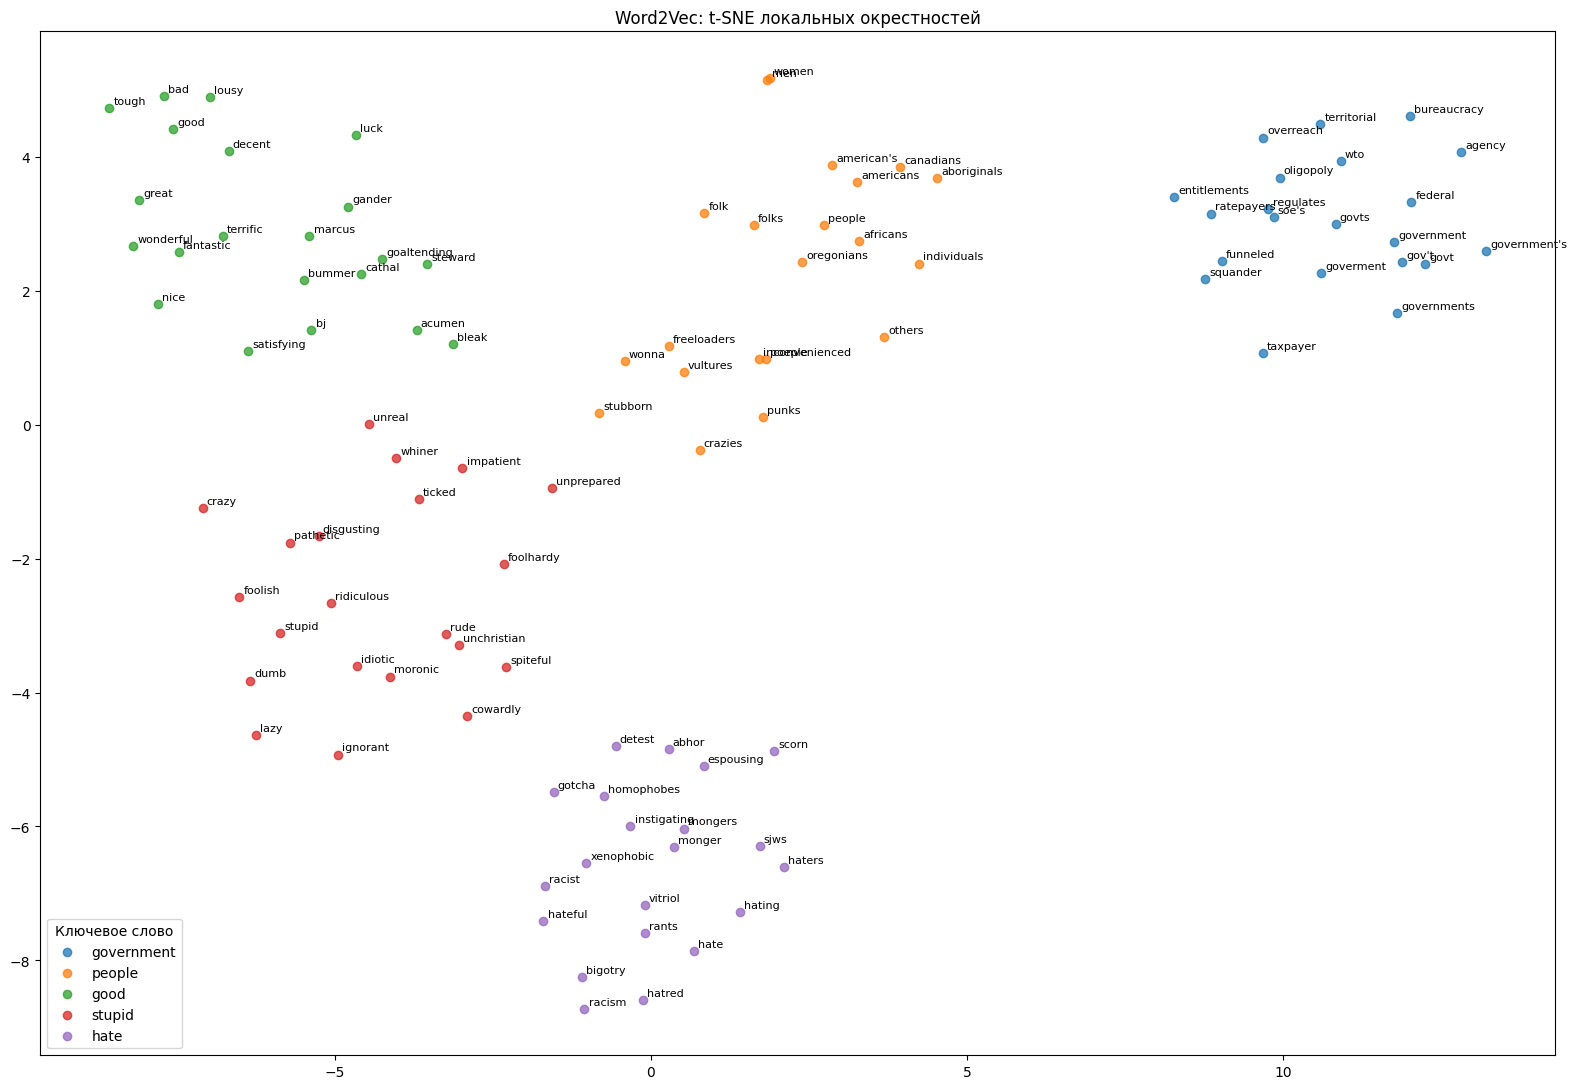

In [36]:
wv = models["Word2Vec"].wv
groups = {word: word for word in keywords}
for keyword in keywords:
    added = 0
    for word, _ in wv.most_similar(keyword, topn=100):
        if word not in groups:
            groups[word] = keyword
            added += 1
        if added == 20:
            break

words = list(groups)
print("Слов на графике:", len(words))
xy = TSNE(
    n_components=2, metric="cosine", perplexity=20,
    init="pca", learning_rate="auto", random_state=SEED,
).fit_transform(wv[words])

fig, ax = plt.subplots(figsize=(16, 11))
for keyword in keywords:
    indices = [i for i, word in enumerate(words) if groups[word] == keyword]
    ax.scatter(xy[indices, 0], xy[indices, 1], label=keyword, alpha=0.75)
for i, word in enumerate(words):
    ax.annotate(word, xy[i], fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.legend(title="Ключевое слово")
ax.set_title("Word2Vec: t-SNE локальных окрестностей")
plt.tight_layout()
plt.show()

## Шаг 2. Промежуточный Baseline (Sentence Embeddings)

In [37]:
def mean_pool(tokens, wv):
    vectors = [wv[token] for token in tokens if token in wv]
    return np.mean(vectors, axis=0) if vectors else np.zeros(wv.vector_size, dtype=np.float32)


In [38]:
classifiers = {}
baseline_results = []

for name, model in models.items():
    start = perf_counter()
    X_train = np.vstack([mean_pool(tokens, model.wv) for tokens in train["tokens"]])
    X_valid = np.vstack([mean_pool(tokens, model.wv) for tokens in valid["tokens"]])
    vectorization_seconds = perf_counter() - start

    clf = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)
    start = perf_counter()
    clf.fit(X_train, train["label"])
    fit_seconds = perf_counter() - start
    classifiers[name] = clf

    predictions = clf.predict(X_valid)
    precision, recall, f1, _ = precision_recall_fscore_support(
        valid["label"], predictions, average="macro", zero_division=0,
    )
    baseline_results.append({
        "embedding": name, "precision_macro": precision,
        "recall_macro": recall, "f1_macro": f1,
        "vectorization_seconds": vectorization_seconds, "fit_seconds": fit_seconds,
    })
    print(f"{name}: Validation Macro F1 = {f1:.4f}", flush=True)

baseline_results = pd.DataFrame(baseline_results)
display(baseline_results.round(4))

Word2Vec: Validation Macro F1 = 0.5782
FastText: Validation Macro F1 = 0.5848


,embedding,precision_macro,recall_macro,f1_macro,vectorization_seconds,fit_seconds
0,Word2Vec,0.5827,0.7284,0.5782,9.9125,0.8055
1,FastText,0.5857,0.7313,0.5848,13.2714,0.8937


## Шаг 3. Рекуррентная нейросеть

Определим max_len на основе распределения tokens выше

In [39]:
MAX_LEN = 256

In [40]:
wv = models["Word2Vec"].wv

# 0 — PAD
# 1 — UNK
vocab = {word: i + 2 for i, word in enumerate(wv.index_to_key)}

In [41]:
def encode_texts(texts):
    X = torch.zeros((len(texts), MAX_LEN), dtype=torch.long)
    for i, tokens in enumerate(texts):
        ids = [vocab.get(token, 1) for token in tokens[:MAX_LEN]] or [1]
        X[i, :len(ids)] = torch.tensor(ids)
    return X

In [42]:
X_train_rnn = encode_texts(train["tokens"])
X_valid_rnn = encode_texts(valid["tokens"])
y_train_rnn = torch.tensor(train["label"].to_numpy(), dtype=torch.long)
y_valid_rnn = torch.tensor(valid["label"].to_numpy(), dtype=torch.long)

embedding_matrix = torch.zeros((len(vocab) + 2, wv.vector_size))
embedding_matrix[1] = torch.from_numpy(wv.vectors.mean(axis=0))
embedding_matrix[2:] = torch.from_numpy(wv.vectors)
print(f"Доля Train длиннее {MAX_LEN} токенов: {train['tokens'].map(len).gt(MAX_LEN).mean():.4%}")

Доля Train длиннее 256 токенов: 0.0047%


In [43]:
class BiGRU(nn.Module):
    def __init__(self, static=False):
        super().__init__()
        if static:
            self.embedding = nn.Embedding.from_pretrained(
                embedding_matrix.clone(), freeze=True, padding_idx=0,
            )
        else:
            self.embedding = nn.Embedding(len(vocab) + 2, wv.vector_size, padding_idx=0)
        self.gru = nn.GRU(wv.vector_size, 64, batch_first=True, bidirectional=True)
        self.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(128, 2))

    def forward(self, x):
        lengths = x.ne(0).sum(dim=1).cpu()
        packed = pack_padded_sequence(
            self.embedding(x), lengths, batch_first=True, enforce_sorted=False,
        )
        _, hidden = self.gru(packed)
        return self.classifier(torch.cat([hidden[-2], hidden[-1]], dim=1))


In [44]:
counts = torch.bincount(y_train_rnn, minlength=2).float()
weights = (len(y_train_rnn) / (2 * counts)).to(device)
criterion = nn.CrossEntropyLoss(weight=weights)

batch_size = 128

dataset = TensorDataset(X_train_rnn, y_train_rnn)
train_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
train_eval_loader = DataLoader(dataset, batch_size=batch_size)
valid_loader = DataLoader(TensorDataset(X_valid_rnn, y_valid_rnn), batch_size=batch_size)


Функция обучения

In [45]:
def train_model(net, optimizer, criterion, train_loader, train_eval_loader,
                valid_loader, checkpoint, epochs=30, patience=3):
    device = next(net.parameters()).device
    weights = criterion.weight

    def evaluate(loader):
        net.eval()
        total_loss, total_weight = 0.0, 0.0
        targets, predictions = [], []
        with torch.no_grad():
            for x, y in loader:
                x, y = x.to(device), y.to(device)
                logits = net(x)
                batch_weight = weights[y].sum().item()
                total_loss += criterion(logits, y).item() * batch_weight
                total_weight += batch_weight
                targets.extend(y.cpu().tolist())
                predictions.extend(logits.argmax(dim=1).cpu().tolist())
        return total_loss / total_weight, f1_score(targets, predictions, average="macro", zero_division=0)

    best_loss, stale = float("inf"), 0
    history = []
    start = perf_counter()
    for epoch in range(1, epochs + 1):
        net.train()
        for x, y in tqdm(train_loader, desc=f"Epoch {epoch}/{epochs}", leave=False):
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(net(x), y)
            loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            optimizer.step()

        train_loss, train_f1 = evaluate(train_eval_loader)
        valid_loss, valid_f1 = evaluate(valid_loader)
        history.append(dict(epoch=epoch, train_loss=train_loss, valid_loss=valid_loss,
                            train_f1=train_f1, valid_f1=valid_f1))
        print(f"Epoch {epoch}: loss {train_loss:.4f}/{valid_loss:.4f}, "
              f"Macro F1 {train_f1:.4f}/{valid_f1:.4f} (train/val)")

        if valid_loss < best_loss:
            best_loss, stale = valid_loss, 0
            best_state = {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}
            torch.save(best_state, checkpoint)
            print("Сохранена лучшая модель")
        else:
            stale += 1
            if stale >= patience:
                print("Early Stopping")
                break

    net.load_state_dict(best_state)
    best_model = net.cpu().eval()
    return best_model, pd.DataFrame(history), perf_counter() - start


In [46]:
SAVE_DIR = Path("lab4_models")
SAVE_DIR.mkdir(exist_ok=True)

# Словарь и длина нужны для применения сохранённых весов к новым текстам.
torch.save({"vocab": vocab, "max_len": MAX_LEN}, SAVE_DIR / "rnn_preprocessing.pt")

Static


Epoch 1/30:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 1: loss 0.4284/0.4363, Macro F1 0.6492/0.6495 (train/val)
Сохранена лучшая модель


Epoch 2/30:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 2: loss 0.3854/0.4002, Macro F1 0.6625/0.6631 (train/val)
Сохранена лучшая модель


Epoch 3/30:   0%|          | 0/500 [00:00<?, ?it/s]

... (9 outputs left out)

Epoch 8/30:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 8: loss 0.2802/0.3826, Macro F1 0.7155/0.6855 (train/val)


Epoch 9/30:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 9: loss 0.2657/0.4151, Macro F1 0.7751/0.7331 (train/val)
Early Stopping


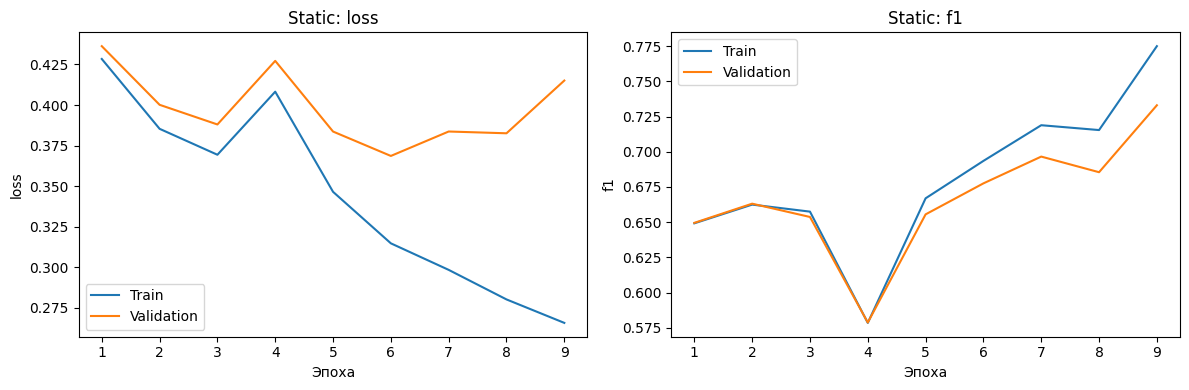

Dynamic


Epoch 1/30:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 1: loss 0.5397/0.5877, Macro F1 0.5249/0.5085 (train/val)
Сохранена лучшая модель


Epoch 2/30:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 2: loss 0.3157/0.4508, Macro F1 0.7156/0.6659 (train/val)
Сохранена лучшая модель


Epoch 3/30:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 3: loss 0.2216/0.4949, Macro F1 0.8096/0.7306 (train/val)


Epoch 4/30:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 4: loss 0.1615/0.4823, Macro F1 0.8244/0.7157 (train/val)


Epoch 5/30:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 5: loss 0.1074/0.5912, Macro F1 0.8598/0.7217 (train/val)
Early Stopping


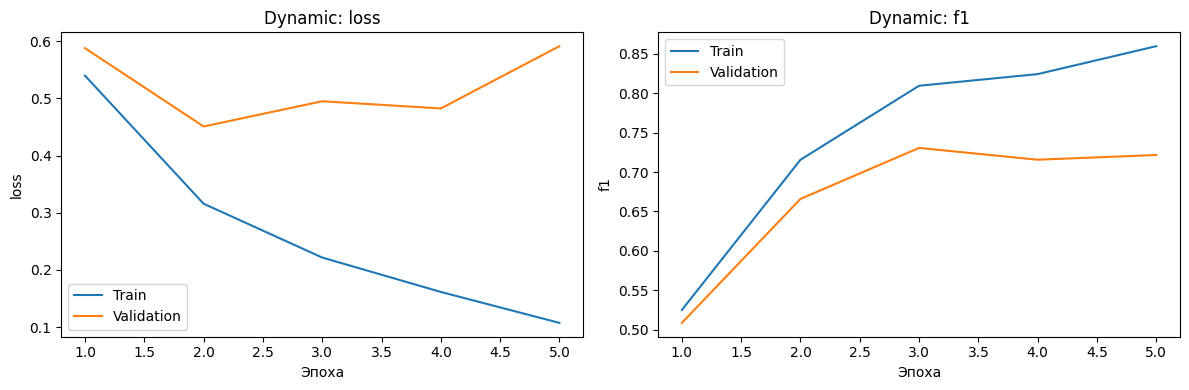

In [47]:
rnn_models, rnn_histories, rnn_times = {}, {}, {}
for name, static in [("Static", True), ("Dynamic", False)]:
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    print(name)
    net = BiGRU(static=static).to(device)
    optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)
    best_model, history, seconds = train_model(
        net, optimizer, criterion, train_loader, train_eval_loader, valid_loader,
        checkpoint=SAVE_DIR / f"bigru_{name.lower()}.pt",
    )
    rnn_models[name], rnn_histories[name], rnn_times[name] = best_model, history, seconds

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric in zip(axes, ["loss", "f1"]):
        ax.plot(history["epoch"], history[f"train_{metric}"], label="Train")
        ax.plot(history["epoch"], history[f"valid_{metric}"], label="Validation")
        ax.set(xlabel="Эпоха", ylabel=metric, title=f"{name}: {metric}")
        ax.legend()
    plt.tight_layout()
    plt.show()


В режиме Dynamic наблюдается переобучение: Train Macro F1 увеличивается до 0,8598, тогда как Validation Macro F1 после третьей эпохи не улучшается. В режиме Static разрыв между Train и Validation меньше.

Лучшая модель выбиралась по минимальному Validation Loss: для Static сохранена эпоха 6, для Dynamic — эпоха 2. Early Stopping завершил обучение на эпохах 9 и 5 соответственно.

Минимум Loss не обязан совпадать с максимумом F1: Loss учитывает уверенность предсказаний и веса классов, а F1 рассчитывается по итоговым меткам. Поэтому на Test оцениваются модели с минимальным Validation Loss, даже если на другой эпохе Validation F1 был выше.

## Шаг 4. Классические модели из lab3 в одинаковых условиях

Повторно обучаем LinearSVC и MultinomialNB на текущих train комментариях. Обе используют TF-IDF и текущую токенизацию `clean`.

Параметры классификаторов сохраняем из lab3.

Словарь и IDF строим только на Train.

In [48]:

start = perf_counter()
bow = CountVectorizer(analyzer=tokenize)
X_train_bow = bow.fit_transform(train["comment_text"])
tfidf = TfidfTransformer()
X_train_tfidf = tfidf.fit_transform(X_train_bow)
tfidf_seconds = perf_counter() - start
X_valid_tfidf = tfidf.transform(bow.transform(valid["comment_text"]))

classic_models = {
    "LinearSVC": LinearSVC(C=1.0, class_weight="balanced", random_state=SEED, max_iter=10_000),
    "MultinomialNB": MultinomialNB(alpha=1.0),
}
classic_times = {}
sample_weights = compute_sample_weight("balanced", train["label"])
for name, clf in classic_models.items():
    start = perf_counter()
    if name == "MultinomialNB":
        clf.fit(X_train_tfidf, train["label"], sample_weight=sample_weights)
    else:
        clf.fit(X_train_tfidf, train["label"])
    classic_times[name] = perf_counter() - start
    score = f1_score(valid["label"], clf.predict(X_valid_tfidf), average="macro")
    print(f"{name}: Validation Macro F1={score:.4f}, обучение {classic_times[name]:.1f} сек.")


LinearSVC: Validation Macro F1=0.7565, обучение 2.1 сек.
MultinomialNB: Validation Macro F1=0.6097, обучение 0.0 сек.


## Шаг 5. Fine-tuning

Для английских комментариев использую[distilbert-base-uncased](https://huggingface.co/distilbert/distilbert-base-uncased).

Дообучаю все веса ([Hugging Face](https://huggingface.co/docs/transformers/tasks/sequence_classification)).

In [58]:
BERT_MAX_LEN = 256

# "prajjwal1/bert-mini"
MODEL_NAME = "prajjwal1/bert-mini"

# AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer = AutoTokenizer.from_pretrained("google-bert/bert-base-uncased")

In [59]:
def encode_transformer(texts):
    encoded = tokenizer(
        texts.tolist(), padding="max_length", truncation=True,
        max_length=BERT_MAX_LEN, return_tensors="pt",
    )
    # Одна пара тензоров на документ: input_ids и attention_mask.
    return torch.stack([encoded["input_ids"], encoded["attention_mask"]], dim=1)

In [60]:
X_train_bert = encode_transformer(train["comment_text"])
X_valid_bert = encode_transformer(valid["comment_text"])
bert_train_data = TensorDataset(X_train_bert, y_train_rnn)
bert_train_loader = DataLoader(bert_train_data, batch_size=16, shuffle=True)
bert_train_eval_loader = DataLoader(bert_train_data, batch_size=16)
bert_valid_loader = DataLoader(TensorDataset(X_valid_bert, y_valid_rnn), batch_size=16)

In [61]:
class TransformerClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        config = BertConfig.from_pretrained(MODEL_NAME, num_labels=2)
        self.model = BertForSequenceClassification.from_pretrained(MODEL_NAME, config=config)
        # self.model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)

    def forward(self, x):
        return self.model(input_ids=x[:, 0], attention_mask=x[:, 1]).logits

In [62]:
torch.manual_seed(SEED)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 45.1MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: prajjwal1/bert-mini
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were 

Epoch 1/3:   0%|          | 0/4000 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 45.1MB            

... (3 outputs left out)

Epoch 2: loss 0.3169/0.5076, Macro F1 0.8477/0.7977 (train/val)


Epoch 3/3:   0%|          | 0/4000 [00:00<?, ?it/s]

Epoch 3: loss 0.2627/0.5899, Macro F1 0.8814/0.8015 (train/val)
Early Stopping


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

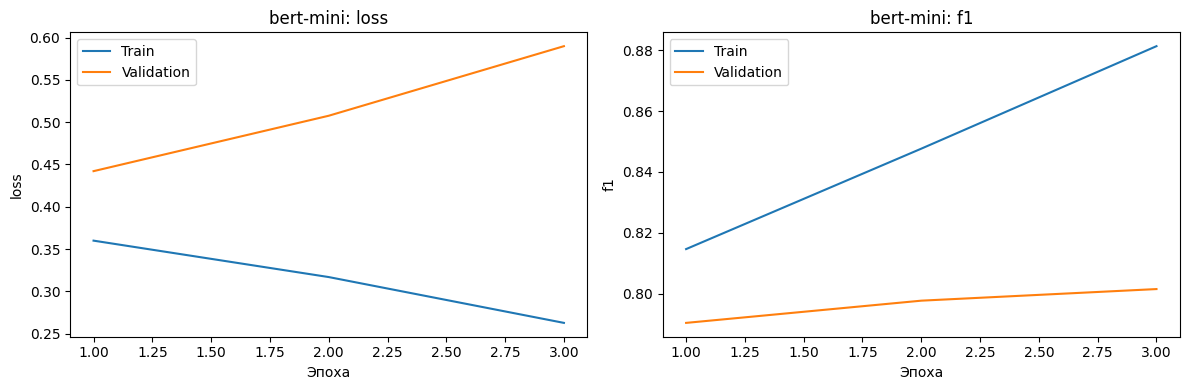

In [63]:
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
net = TransformerClassifier().to(device)
optimizer = torch.optim.AdamW(net.parameters(), lr=2e-5)
best_transformer, bert_history, bert_seconds = train_model(
    net, optimizer, criterion, bert_train_loader, bert_train_eval_loader,
    bert_valid_loader, checkpoint=SAVE_DIR / "bert-mini_best.pt", epochs=3, patience=2,
)


best_transformer.model.save_pretrained(SAVE_DIR / "bert-mini")
tokenizer.save_pretrained(SAVE_DIR / "bert-mini")
del optimizer, net

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["loss", "f1"]):
    ax.plot(bert_history["epoch"], bert_history[f"train_{metric}"], label="Train")
    ax.plot(bert_history["epoch"], bert_history[f"valid_{metric}"], label="Validation")
    ax.set(xlabel="Эпоха", ylabel=metric, title=f"bert-mini: {metric}")
    ax.legend()
plt.tight_layout()
plt.show()


## Шаг 6. Итоговая оценка на Test

In [64]:
def predict_batches(net, X, batch_size=128):
    net = net.to(device).eval()
    predictions = []
    with torch.no_grad():
        for (x,) in tqdm(DataLoader(TensorDataset(X), batch_size=batch_size), desc="Test", leave=False):
            predictions.extend(net(x.to(device)).argmax(dim=1).cpu().tolist())
    net.cpu()
    return np.array(predictions)

In [65]:
test_predictions = {}
X_test_tfidf = tfidf.transform(bow.transform(test["comment_text"]))
for name, clf in classic_models.items():
    test_predictions[name] = clf.predict(X_test_tfidf)

for name, model in models.items():
    X_test_mean = np.vstack([mean_pool(tokens, model.wv) for tokens in test["tokens"]])
    test_predictions[f"{name} + LR"] = classifiers[name].predict(X_test_mean)

X_test_rnn = encode_texts(test["tokens"])
for name, net in rnn_models.items():
    test_predictions[f"BiGRU {name}"] = predict_batches(net, X_test_rnn)

X_test_bert = encode_transformer(test["comment_text"])
test_predictions["bert-mini"] = predict_batches(best_transformer, X_test_bert, batch_size=16)


Test:   0%|          | 0/157 [00:00<?, ?it/s]

Test:   0%|          | 0/157 [00:00<?, ?it/s]

Test:   0%|          | 0/1250 [00:00<?, ?it/s]

In [66]:
rows = []
for name, predictions in test_predictions.items():
    precision, recall, f1, _ = precision_recall_fscore_support(
        test["label"], predictions, average="macro", zero_division=0,
    )
    rows.append({"model": name, "precision_macro": precision,
                 "recall_macro": recall, "f1_macro": f1})

benchmark = pd.DataFrame(rows).set_index("model")
benchmark["features"] = pd.Series({
    "LinearSVC": "TF-IDF, clean", "MultinomialNB": "TF-IDF, clean",
    "Word2Vec + LR": "Mean Pooling", "FastText + LR": "Mean Pooling",
    "BiGRU Static": "Word2Vec frozen", "BiGRU Dynamic": "Embedding from scratch",
    "bert-mini": "Fine-tuning, raw text",
})
fit_times = dict(classic_times)
feature_times = {name: tfidf_seconds for name in classic_models}
for row in baseline_results.itertuples(index=False):
    name = f"{row.embedding} + LR"
    fit_times[name] = row.fit_seconds
    feature_times[name] = embedding_times[row.embedding]
for name, seconds in rnn_times.items():
    fit_times[f"BiGRU {name}"] = seconds
    feature_times[f"BiGRU {name}"] = embedding_times["Word2Vec"] if name == "Static" else 0
fit_times["bert-mini"] = bert_seconds
feature_times["bert-mini"] = 0
benchmark["fit_seconds"] = pd.Series(fit_times)
benchmark["feature_training_seconds"] = pd.Series(feature_times)
benchmark["train_documents"] = len(train)
display(benchmark.round(4))
benchmark.to_csv(SAVE_DIR / "benchmark.csv")
pd.DataFrame(test_predictions, index=test.index).rename_axis("source_id").to_csv(
    SAVE_DIR / "test_predictions.csv",
)

,precision_macro,recall_macro,f1_macro,features,fit_seconds,feature_training_seconds,train_documents
model,,,,,,,
LinearSVC,0.7211,0.7773,0.7448,"TF-IDF, clean",2.0501,6.7684,64000
MultinomialNB,0.6025,0.7673,0.6114,"TF-IDF, clean",0.0325,6.7684,64000
Word2Vec + LR,0.5811,0.7197,0.5782,Mean Pooling,0.8055,166.7497,64000
FastText + LR,0.5846,0.7251,0.5848,Mean Pooling,0.8937,324.7067,64000
BiGRU Static,0.6437,0.8276,0.6749,Word2Vec frozen,158.1911,166.7497,64000
BiGRU Dynamic,0.6304,0.7865,0.6581,Embedding from scratch,96.4506,0.0000,64000
bert-mini,0.7580,0.8207,0.7848,"Fine-tuning, raw text",667.3712,0.0000,64000


In [67]:
lab3_reference = pd.DataFrame([
    {"model": "LinearSVC", "features": "TF-IDF, clean", "precision_macro": 0.7229,
     "recall_macro": 0.7893, "f1_macro": 0.7502, "train_documents": 80_000},
    {"model": "MultinomialNB", "features": "TF-IDF, lemma", "precision_macro": 0.6034,
     "recall_macro": 0.7724, "f1_macro": 0.6115, "train_documents": 80_000},
])
display(lab3_reference)


,model,features,precision_macro,recall_macro,f1_macro,train_documents
0,LinearSVC,"TF-IDF, clean",0.7229,0.7893,0.7502,80000
1,MultinomialNB,"TF-IDF, lemma",0.6034,0.7724,0.6115,80000


LinearSVC
              precision    recall  f1-score   support

           0     0.9655    0.9415    0.9533     18400
           1     0.4767    0.6131    0.5364      1600

    accuracy                         0.9152     20000
   macro avg     0.7211    0.7773    0.7448     20000
weighted avg     0.9264    0.9152    0.9200     20000

MultinomialNB
              precision    recall  f1-score   support

           0     0.9731    0.7839    0.8683     18400
           1     0.2320    0.7506    0.3544      1600

    accuracy                         0.7812     20000
   macro avg     0.6025    0.7673    0.6114     20000
weighted avg     0.9138    0.7812    0.8272     20000

Word2Vec + LR
              precision    recall  f1-score   support

           0     0.9646    0.7601    0.8502     18400
           1     0.1976    0.6794    0.3062      1600

    accuracy                         0.7537     20000
   macro avg     0.5811    0.7197    0.5782     20000
weighted avg     0.9033    0.7537   

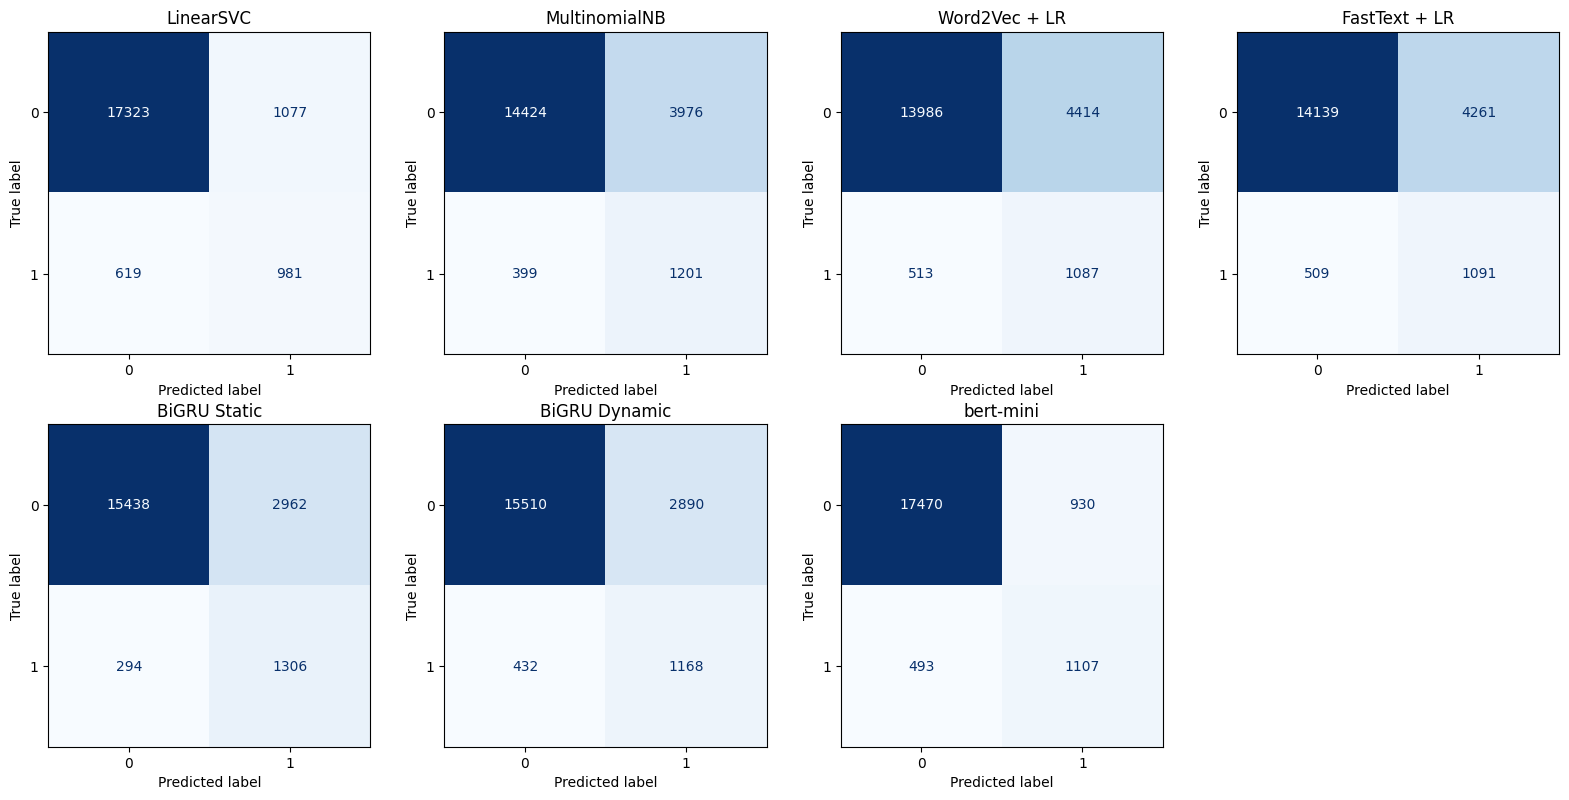

In [68]:
for name, predictions in test_predictions.items():
    print(name)
    print(classification_report(test["label"], predictions, digits=4, zero_division=0))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (name, predictions) in zip(axes.flat, test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        test["label"], predictions, labels=[0, 1], ax=ax, colorbar=False, cmap="Blues",
    )
    ax.set_title(name)
for ax in axes.flat[len(test_predictions):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()


Лучший результат на Test показал BERT-Mini: Macro F1=0,7848 против 0,7448 у LinearSVC. Для токсичного класса BERT-Mini одновременно повысил Precision с 0,4767 до 0,5434 и Recall с 0,6131 до 0,6919. Число ложных срабатываний снизилось с 1077 до 930, а пропусков токсичности — с 619 до 493.

BiGRU Static обнаружила 1306 из 1600 токсичных комментариев — больше остальных моделей, однако дала 2962 ложных срабатывания. Поэтому её высокий Recall сопровождается сравнительно низким Precision, а Macro F1 составляет 0,6749. Dynamic уступила Static: Macro F1=0,6581.

FastText с усреднением немного превзошёл Word2Vec: Macro F1=0,5848 против 0,5782. Оба варианта уступили TF-IDF-классификаторам. Это показывает, что плотные векторы и их простое усреднение не гарантируют преимущества перед разреженными лексическими признаками на данном датасете.

## Вывод

На данном датасете лучшее качество показал BERT-Mini: Test Macro F1=0,7848. Его преимущество согласуется с использованием контекстных представлений и предварительного обучения на внешнем корпусе, однако вклад этих факторов отдельно в работе не измерялся.

LinearSVC с TF-IDF достиг Macro F1=0,7448 при значительно меньших затратах: построение признаков заняло около 7 секунд, обучение классификатора — 2 секунды. Дообучение BERT-Mini вместе с оценкой по эпохам и сохранением весов заняло около 667 секунд на GPU Tesla T4. Поэтому SVM оказался привлекательным вариантом при ограниченных ресурсах, а BERT-Mini — при приоритете качества.

Обе BiGRU превзошли усреднение векторов, но уступили SVM. Учёт последовательности слов оказался недостаточен для преимущества над TF-IDF в выбранных условиях. Dynamic продемонстрировала переобучение; Static показала более высокое итоговое качество. Возможное объяснение силы TF-IDF — сохранение отдельных лексических сигналов токсичности, которые могут ослабляться при усреднении векторов.

Сравнение выполнено на одинаковом Test, все модели текущего эксперимента обучены на 64 000 комментариев. Результаты относятся к выбранным параметрам и одному seed; устойчивость различий не проверялась. Время зависит от среды Colab, а замеры включают разные этапы обработки, поэтому не являются строгим аппаратным бенчмарком.